# Baseline, mô hình và lựa chọn
Mỗi mô hình dự báo 6 khoảng tương lai. Search dùng ba fold mở rộng trong TRAIN. Shortlist theo OOF, chốt theo validation. TEST chỉ được chấm sau khi khóa lựa chọn.

In [1]:
from pathlib import Path
import sys,json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/appliances').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from src.appliances.config import RELEASE,MODEL_DIR,HORIZONS,BOUNDARIES
from src.appliances.data import load_data
from src.appliances.features import supervised,split_rows,make_features,feature_columns
raw,audit=load_data()
rows,columns=supervised(raw)
parts,counts=split_rows(rows)
def read_json(name):
    return json.loads((RELEASE/name).read_text(encoding='utf-8'))


In [2]:
display(pd.Series(read_json("selection.json")))
search=pd.read_csv(RELEASE/"search_metrics.csv")
display(search[search.split.isin(["oof","validation"])][["model","split","mae_step_kWh","mae_hour_kWh","high_mae_hour_kWh","fit_seconds"]])

winner                                                                 G1_xgb_3
candidate                        {'name': 'xgb_3', 'family': 'xgb', 'depth': 3}
features                      [energy_lag_0, energy_lag_1, energy_lag_2, ene...
shortlist                     [G0_xgb_3, G1_xgb_3, G0_hgb_31, G1_hgb_31, G0_...
locked_before_test_scoring                                                 True
criterion                     OOF shortlist, then minimum validation hourly MAE
dtype: object

,model,split,mae_step_kWh,mae_hour_kWh,high_mae_hour_kWh,fit_seconds
3,G0_ridge_1,validation,0.042918,0.216151,1.050973,0.036417
4,G0_ridge_1,oof,0.042614,0.206898,1.037611,NaN
8,G0_ridge_100,validation,0.042838,0.215741,1.051811,0.035352
9,G0_ridge_100,oof,0.042533,0.206460,1.039749,NaN
13,G0_hgb_15,validation,0.034323,0.170257,1.177784,11.030315
14,G0_hgb_15,oof,0.035807,0.174129,1.194104,NaN
18,G0_hgb_31,validation,0.034781,0.168837,1.098587,16.703587
19,G0_hgb_31,oof,0.036472,0.173921,1.146961,NaN
23,G0_xgb_3,validation,0.034312,0.169389,1.169276,5.504312
24,G0_xgb_3,oof,0.035635,0.173148,1.204341,NaN


## Ví dụ huấn luyện Ridge thực sự
Cell sau fit scaler và Ridge trên TRAIN rồi chấm validation. Đây là ví dụ chạy được của quá trình học. Full search HGB/XGBoost được thực hiện bằng `python -m scripts.train_models`, có bảng cấu hình và dự báo OOF đã lưu.

In [3]:
from threadpoolctl import threadpool_limits
from src.appliances.modeling import fit_point,predict_point
from src.appliances.metrics import point_metrics
labels=[f"actual_{m}m_kWh" for m in HORIZONS]
g0=feature_columns(rows[columns],"G0")
with threadpool_limits(limits=1):
    ridge,timing=fit_point(parts["train"][g0],parts["train"][labels].to_numpy(),{"family":"ridge","alpha":100.})
    predicted=predict_point(ridge,parts["validation"][g0])
score=point_metrics(parts["validation"][labels].to_numpy(),predicted,float(parts["train"].actual_hour_kWh.quantile(.95)))
expected=search[(search.model=="G0_ridge_100") & (search.split=="validation")].iloc[0].mae_hour_kWh
assert np.isclose(score["mae_hour_kWh"],expected)
display(pd.Series({"validation_hour_MAE":score["mae_hour_kWh"],"fit_seconds_this_cell":timing["fit_seconds"],"matches_frozen_search":True}))

validation_hour_MAE      0.215741
fit_seconds_this_cell    0.014907
matches_frozen_search        True
dtype: object

,split,model,mae_step_kWh,mae_hour_kWh,high_mae_hour_kWh
0,validation,persistence,0.045963,0.242532,1.274904
1,validation,previous_day,0.058237,0.289463,1.321538
2,validation,previous_week,0.065344,0.321607,1.009231
3,validation,G0_ridge_1,0.042918,0.216151,1.050973
4,validation,G0_ridge_100,0.042838,0.215741,1.051811
5,validation,G0_hgb_15,0.034323,0.170257,1.177784
6,validation,G0_hgb_31,0.034781,0.168837,1.098587
7,validation,G0_xgb_3,0.034312,0.169389,1.169276
8,validation,G0_xgb_5,0.034639,0.169426,1.138479
9,validation,G1_ridge_1,0.043052,0.214828,1.033949


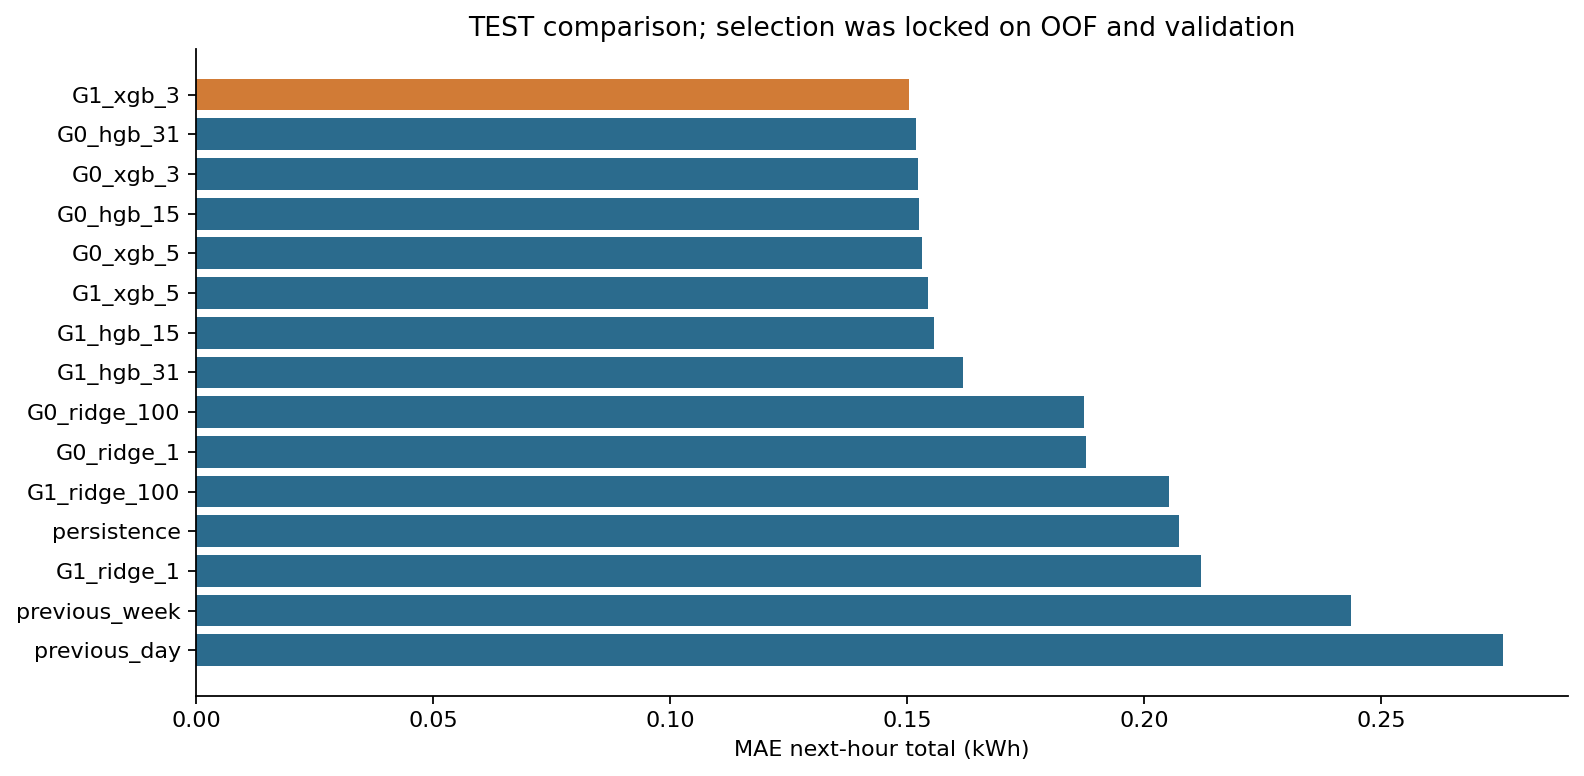

In [4]:
comparison=pd.read_csv(RELEASE/"comparison.csv")
display(comparison[["split","model","mae_step_kWh","mae_hour_kWh","high_mae_hour_kWh"]])
display(Image(filename=str(RELEASE/"figures/04_models.png")))

In [5]:
ablation=read_json("ablation.json")
display(pd.DataFrame(ablation)[["ablation","features","mae_hour_kWh"]])
display(read_json("gpu_benchmark.json"))

,ablation,features,mae_hour_kWh
0,without_day_lag,37,0.168601
1,without_week_lag,37,0.168009
2,without_rolling,33,0.171622


{'cpu': {'timing': {'fit_seconds': 7.398696199990809,
   'devices': ['cpu', 'cpu', 'cpu', 'cpu', 'cpu', 'cpu']},
  'validation': {'rows': 2010,
   'mae_step_kWh': 0.03466365318453776,
   'rmse_step_kWh': 0.08418001661809367,
   'mae_hour_kWh': 0.16780066100052043,
   'rmse_hour_kWh': 0.35539903607583084,
   'bias_hour_kWh': -0.07976750771908915,
   'high_rows': 104,
   'high_mae_hour_kWh': 1.1359494446418608,
   'horizons': [{'minutes': 10,
     'mae_kWh': 0.024488616123276564,
     'rmse_kWh': 0.06438109713427138},
    {'minutes': 20,
     'mae_kWh': 0.03235334609100475,
     'rmse_kWh': 0.08408839774736794},
    {'minutes': 30,
     'mae_kWh': 0.035552653332551316,
     'rmse_kWh': 0.08727914160056825},
    {'minutes': 40,
     'mae_kWh': 0.037367475752732644,
     'rmse_kWh': 0.08913469762559807},
    {'minutes': 50,
     'mae_kWh': 0.03841689400070935,
     'rmse_kWh': 0.08990134012401839},
    {'minutes': 60,
     'mae_kWh': 0.03980293380695196,
     'rmse_kWh': 0.0902954254767379

## Giải thích giới hạn
Các cấu hình ít và cố định giúp kiểm nghiệm trong ngân sách nhỏ. GPU được xác minh bằng cấu hình booster, chi phí được đo bằng thời gian. Chưa đo điện năng GPU hoặc tiền thuê. Chưa có bằng chứng tối ưu toàn cục.